salvo em heatmaps.png


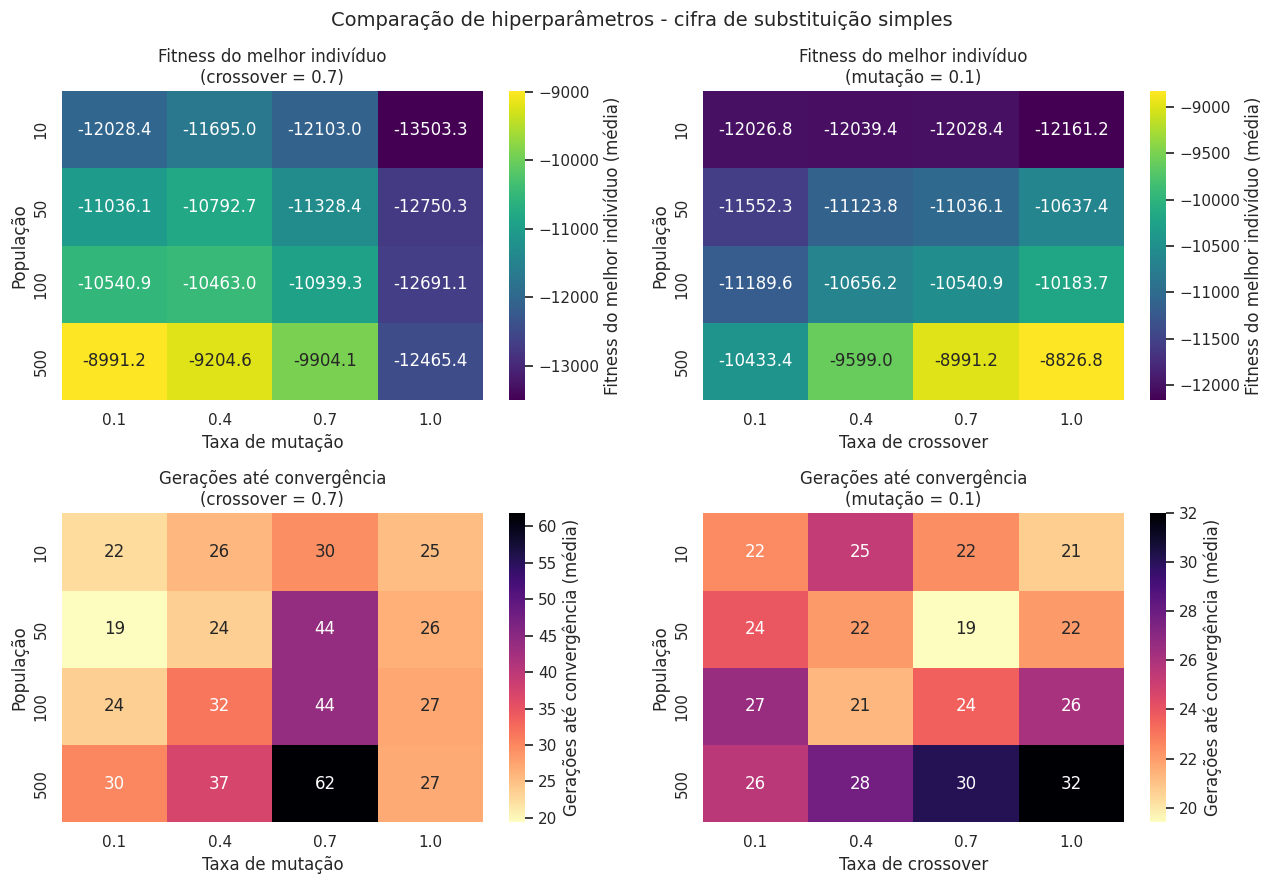

In [7]:
"""Mapas de calor do experimento heatmap_experiment.py.

Google Colab:
  1. envie este arquivo (ou cole o conteúdo numa célula);
  2. rode `%run plot_heatmaps.py`; se o CSV não estiver no Colab, ele pede o upload.
seaborn, pandas e matplotlib já vêm instalados no Colab.
"""
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

CSV_PATH = "simple_heatmap.csv"   # ou "circ_heatmap.csv"
OUT_PNG = "heatmaps.png"
BASE_MUT = 0.1   # mutação fixa no mapa população x crossover (mesmo valor do prog.py)
BASE_CX = 0.7    # crossover fixo no mapa população x mutação (mesmo valor do prog.py)

# --- carregar o CSV (no Colab, pede o upload se o arquivo não estiver lá) ---
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        print(f"{CSV_PATH} não encontrado: selecione o CSV para enviar.")
        files.upload()
    except ImportError:
        pass
if not os.path.exists(CSV_PATH):
    raise SystemExit(f"arquivo não encontrado: {CSV_PATH} (ajuste CSV_PATH)")

df = pd.read_csv(CSV_PATH)

# --- uma linha por execução: fitness final e gerações até parar ---
KEYS = ["pop_size", "mutation_rate", "crossover_rate", "run"]
df = df.sort_values(KEYS + ["generation"])
runs = df.groupby(KEYS).agg(
    final_best=("best_fitness", "last"),   # melhor fitness da última geração
    generations=("generation", "max"),     # última geração da execução
).reset_index()

# --- aviso se alguma combinação não tem o mesmo número de execuções ---
counts = runs.groupby(["pop_size", "mutation_rate", "crossover_rate"]).size()
if counts.nunique() > 1:
    print("AVISO: combinações com número diferente de execuções (experimento incompleto?):")
    print(counts[counts != counts.max()])

# --- as duas fatias do experimento ---
mut_sweep = runs[runs["crossover_rate"] == BASE_CX]   # população x mutação
cx_sweep = runs[runs["mutation_rate"] == BASE_MUT]    # população x crossover
if mut_sweep.empty or cx_sweep.empty:
    raise SystemExit("nenhuma linha com os valores fixos; confira BASE_MUT e BASE_CX")

panels = [
    (mut_sweep, "mutation_rate", "Taxa de mutação", f"(crossover = {BASE_CX})"),
    (cx_sweep, "crossover_rate", "Taxa de crossover", f"(mutação = {BASE_MUT})"),
]
metrics = [
    ("final_best", "Fitness do melhor indivíduo", ".1f", "viridis"),
    ("generations", "Gerações até convergência", ".0f", "magma_r"),
]

fig, axes = plt.subplots(len(metrics), len(panels), figsize=(13, 9))
for r, (metric, metric_label, fmt, cmap) in enumerate(metrics):
    for c, (data, x_col, x_label, fixed) in enumerate(panels):
        table = data.pivot_table(
            index="pop_size", columns=x_col, values=metric, aggfunc="mean"
        )
        ax = axes[r][c]
        sns.heatmap(
            table, ax=ax, annot=True, fmt=fmt, cmap=cmap,
            cbar_kws={"label": f"{metric_label} (média)"},
        )
        ax.set_title(f"{metric_label}\n{fixed}")
        ax.set_xlabel(x_label)
        ax.set_ylabel("População")

n_runs = runs.groupby(["pop_size", "mutation_rate", "crossover_rate"]).size().max()
fig.suptitle(f"Comparação de hiperparâmetros - cifra de substituição simples", fontsize=14)
fig.tight_layout()
fig.savefig(OUT_PNG, dpi=150)
print("salvo em", OUT_PNG)
plt.show()

# No Colab, para baixar a imagem:
#   from google.colab import files; files.download(OUT_PNG)

salvo em heatmaps.png


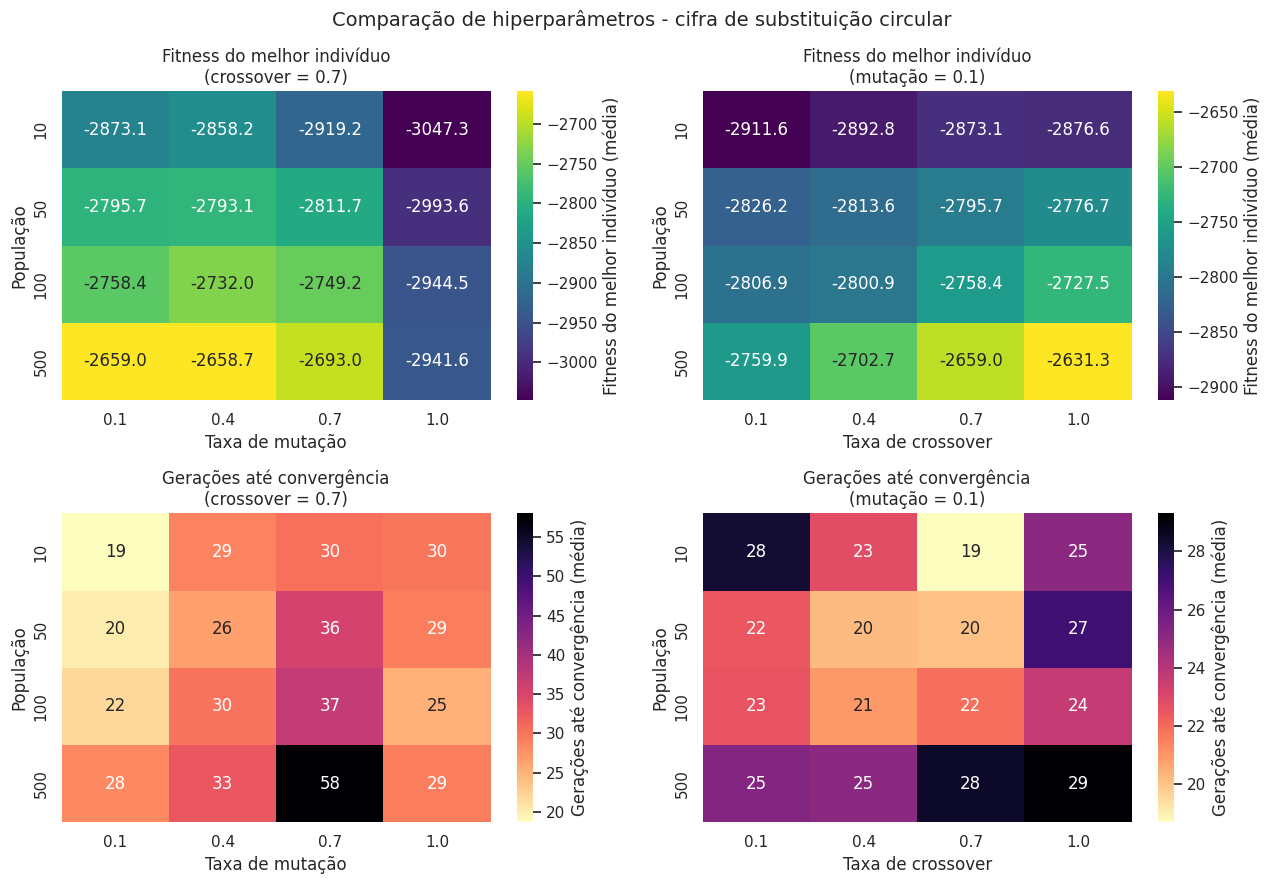

In [8]:
"""Mapas de calor do experimento heatmap_experiment.py.

Google Colab:
  1. envie este arquivo (ou cole o conteúdo numa célula);
  2. rode `%run plot_heatmaps.py`; se o CSV não estiver no Colab, ele pede o upload.
seaborn, pandas e matplotlib já vêm instalados no Colab.
"""
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

CSV_PATH = "circ_heatmap.csv"
OUT_PNG = "heatmaps.png"
BASE_MUT = 0.1   # mutação fixa no mapa população x crossover (mesmo valor do prog.py)
BASE_CX = 0.7    # crossover fixo no mapa população x mutação (mesmo valor do prog.py)

# --- carregar o CSV (no Colab, pede o upload se o arquivo não estiver lá) ---
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        print(f"{CSV_PATH} não encontrado: selecione o CSV para enviar.")
        files.upload()
    except ImportError:
        pass
if not os.path.exists(CSV_PATH):
    raise SystemExit(f"arquivo não encontrado: {CSV_PATH} (ajuste CSV_PATH)")

df = pd.read_csv(CSV_PATH)

# --- uma linha por execução: fitness final e gerações até parar ---
KEYS = ["pop_size", "mutation_rate", "crossover_rate", "run"]
df = df.sort_values(KEYS + ["generation"])
runs = df.groupby(KEYS).agg(
    final_best=("best_fitness", "last"),   # melhor fitness da última geração
    generations=("generation", "max"),     # última geração da execução
).reset_index()

# --- aviso se alguma combinação não tem o mesmo número de execuções ---
counts = runs.groupby(["pop_size", "mutation_rate", "crossover_rate"]).size()
if counts.nunique() > 1:
    print("AVISO: combinações com número diferente de execuções (experimento incompleto?):")
    print(counts[counts != counts.max()])

# --- as duas fatias do experimento ---
mut_sweep = runs[runs["crossover_rate"] == BASE_CX]   # população x mutação
cx_sweep = runs[runs["mutation_rate"] == BASE_MUT]    # população x crossover
if mut_sweep.empty or cx_sweep.empty:
    raise SystemExit("nenhuma linha com os valores fixos; confira BASE_MUT e BASE_CX")

panels = [
    (mut_sweep, "mutation_rate", "Taxa de mutação", f"(crossover = {BASE_CX})"),
    (cx_sweep, "crossover_rate", "Taxa de crossover", f"(mutação = {BASE_MUT})"),
]
metrics = [
    ("final_best", "Fitness do melhor indivíduo", ".1f", "viridis"),
    ("generations", "Gerações até convergência", ".0f", "magma_r"),
]

fig, axes = plt.subplots(len(metrics), len(panels), figsize=(13, 9))
for r, (metric, metric_label, fmt, cmap) in enumerate(metrics):
    for c, (data, x_col, x_label, fixed) in enumerate(panels):
        table = data.pivot_table(
            index="pop_size", columns=x_col, values=metric, aggfunc="mean"
        )
        ax = axes[r][c]
        sns.heatmap(
            table, ax=ax, annot=True, fmt=fmt, cmap=cmap,
            cbar_kws={"label": f"{metric_label} (média)"},
        )
        ax.set_title(f"{metric_label}\n{fixed}")
        ax.set_xlabel(x_label)
        ax.set_ylabel("População")

n_runs = runs.groupby(["pop_size", "mutation_rate", "crossover_rate"]).size().max()
fig.suptitle(f"Comparação de hiperparâmetros - cifra de substituição circular", fontsize=14)
fig.tight_layout()
fig.savefig(OUT_PNG, dpi=150)
print("salvo em", OUT_PNG)
plt.show()

# No Colab, para baixar a imagem:
#   from google.colab import files; files.download(OUT_PNG)

salvo em curves.png


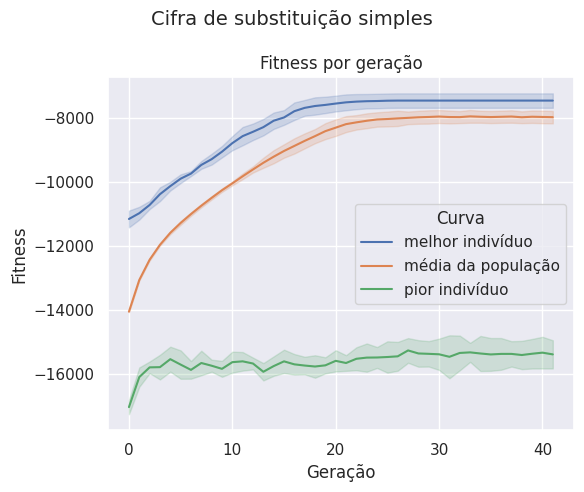

In [10]:
"""Curvas de fitness por geração (média das execuções ± 1 desvio padrão).

Serve para os dois CSVs:
  - experiment.py (uma configuração): curvas do melhor, da média e do pior;
  - heatmap_experiment.py: compara população, mutação e crossover.

Google Colab: envie este arquivo e rode `%run plot_curves.py`
(se o CSV não estiver no Colab, ele pede o upload).
"""
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

CSV_PATH = "simple_experiment.csv"   # ou "simple_experiment.csv", "circ_heatmap.csv"...
OUT_PNG = "curves.png"
COLUMN = "mean_fitness"   # best_fitness, worst_fitness ou mean_fitness (só no CSV do heatmap)

# usados só no CSV do heatmap (mesmos valores do prog.py / heatmap_experiment.py)
BASE_MUT = 0.1
BASE_CX = 0.7
POP_REF = 100   # população usada nos painéis de mutação e crossover

# --- carregar o CSV (no Colab, pede o upload se o arquivo não estiver lá) ---
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        print(f"{CSV_PATH} não encontrado: selecione o CSV para enviar.")
        files.upload()
    except ImportError:
        pass
if not os.path.exists(CSV_PATH):
    raise SystemExit(f"arquivo não encontrado: {CSV_PATH} (ajuste CSV_PATH)")

df = pd.read_csv(CSV_PATH)
if "run" not in df.columns:
    df["run"] = 0
has_config = {"pop_size", "mutation_rate", "crossover_rate"} <= set(df.columns)


def padded(group, column):
    """Uma coluna por execução. As que pararam antes são completadas com o
    último valor (a execução terminou naquele fitness)."""
    return group.pivot(index="generation", columns="run", values=column).ffill()


def long_form(wide, label):
    out = wide.reset_index().melt(id_vars="generation", var_name="run", value_name="fitness")
    out["label"] = label
    return out


def draw(ax, curves, title, legend_title):
    """curves: lista de (rótulo, dados de UMA configuração, coluna)."""
    parts = [long_form(padded(g, col), label) for label, g, col in curves]
    labels = [label for label, _, _ in curves]
    sns.lineplot(
        data=pd.concat(parts), x="generation", y="fitness",
        hue="label", hue_order=labels, errorbar="sd", ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Geração")
    ax.set_ylabel("Fitness")
    ax.legend(title=legend_title)


def sweep(filters, hue):
    """Uma curva por valor de `hue`, com os demais parâmetros fixos em `filters`."""
    sub = df
    for col, val in filters.items():
        sub = sub[sub[col] == val]
    if sub.empty:
        raise SystemExit(f"nenhuma linha com {filters}; confira BASE_MUT, BASE_CX e POP_REF")
    return [(str(v), g, COLUMN) for v, g in sub.groupby(hue)]


sns.set_theme()

if has_config:
    panels = [
        (sweep({"mutation_rate": BASE_MUT, "crossover_rate": BASE_CX}, "pop_size"),
         f"Por população\n(mutação {BASE_MUT}, crossover {BASE_CX})", "População"),
        (sweep({"pop_size": POP_REF, "crossover_rate": BASE_CX}, "mutation_rate"),
         f"Por taxa de mutação\n(população {POP_REF}, crossover {BASE_CX})", "Mutação"),
        (sweep({"pop_size": POP_REF, "mutation_rate": BASE_MUT}, "crossover_rate"),
         f"Por taxa de crossover\n(população {POP_REF}, mutação {BASE_MUT})", "Crossover"),
    ]
else:   # CSV do experiment.py: uma única configuração
    curves = [
        ("melhor indivíduo", df, "best_fitness"),
        ("média da população", df, "mean_fitness"),
        ("pior indivíduo", df, "worst_fitness"),
    ]
    panels = [(curves, "Fitness por geração", "Curva")]

fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 5), sharey=True, squeeze=False)
for ax, (curves, title, legend_title) in zip(axes[0], panels):
    draw(ax, curves, title, legend_title)

n_runs = df["run"].nunique()
fig.suptitle(f"Cifra de substituição simples", fontsize=14)
fig.tight_layout()
fig.savefig(OUT_PNG, dpi=150)
print("salvo em", OUT_PNG)
plt.show()

# No Colab, para baixar a imagem:
#   from google.colab import files; files.download(OUT_PNG)

salvo em curves.png


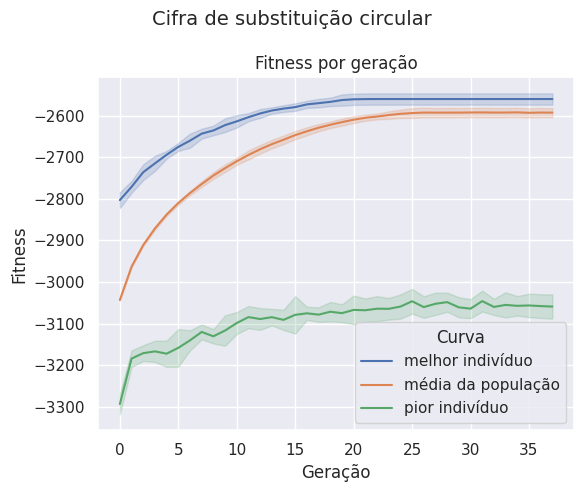

In [11]:
"""Curvas de fitness por geração (média das execuções ± 1 desvio padrão).

Serve para os dois CSVs:
  - experiment.py (uma configuração): curvas do melhor, da média e do pior;
  - heatmap_experiment.py: compara população, mutação e crossover.

Google Colab: envie este arquivo e rode `%run plot_curves.py`
(se o CSV não estiver no Colab, ele pede o upload).
"""
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

CSV_PATH = "circ_experiment.csv"   # ou "simple_experiment.csv", "circ_heatmap.csv"...
OUT_PNG = "curves.png"
COLUMN = "mean_fitness"   # best_fitness, worst_fitness ou mean_fitness (só no CSV do heatmap)

# usados só no CSV do heatmap (mesmos valores do prog.py / heatmap_experiment.py)
BASE_MUT = 0.1
BASE_CX = 0.7
POP_REF = 100   # população usada nos painéis de mutação e crossover

# --- carregar o CSV (no Colab, pede o upload se o arquivo não estiver lá) ---
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        print(f"{CSV_PATH} não encontrado: selecione o CSV para enviar.")
        files.upload()
    except ImportError:
        pass
if not os.path.exists(CSV_PATH):
    raise SystemExit(f"arquivo não encontrado: {CSV_PATH} (ajuste CSV_PATH)")

df = pd.read_csv(CSV_PATH)
if "run" not in df.columns:
    df["run"] = 0
has_config = {"pop_size", "mutation_rate", "crossover_rate"} <= set(df.columns)


def padded(group, column):
    """Uma coluna por execução. As que pararam antes são completadas com o
    último valor (a execução terminou naquele fitness)."""
    return group.pivot(index="generation", columns="run", values=column).ffill()


def long_form(wide, label):
    out = wide.reset_index().melt(id_vars="generation", var_name="run", value_name="fitness")
    out["label"] = label
    return out


def draw(ax, curves, title, legend_title):
    """curves: lista de (rótulo, dados de UMA configuração, coluna)."""
    parts = [long_form(padded(g, col), label) for label, g, col in curves]
    labels = [label for label, _, _ in curves]
    sns.lineplot(
        data=pd.concat(parts), x="generation", y="fitness",
        hue="label", hue_order=labels, errorbar="sd", ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Geração")
    ax.set_ylabel("Fitness")
    ax.legend(title=legend_title)


def sweep(filters, hue):
    """Uma curva por valor de `hue`, com os demais parâmetros fixos em `filters`."""
    sub = df
    for col, val in filters.items():
        sub = sub[sub[col] == val]
    if sub.empty:
        raise SystemExit(f"nenhuma linha com {filters}; confira BASE_MUT, BASE_CX e POP_REF")
    return [(str(v), g, COLUMN) for v, g in sub.groupby(hue)]


sns.set_theme()

if has_config:
    panels = [
        (sweep({"mutation_rate": BASE_MUT, "crossover_rate": BASE_CX}, "pop_size"),
         f"Por população\n(mutação {BASE_MUT}, crossover {BASE_CX})", "População"),
        (sweep({"pop_size": POP_REF, "crossover_rate": BASE_CX}, "mutation_rate"),
         f"Por taxa de mutação\n(população {POP_REF}, crossover {BASE_CX})", "Mutação"),
        (sweep({"pop_size": POP_REF, "mutation_rate": BASE_MUT}, "crossover_rate"),
         f"Por taxa de crossover\n(população {POP_REF}, mutação {BASE_MUT})", "Crossover"),
    ]
else:   # CSV do experiment.py: uma única configuração
    curves = [
        ("melhor indivíduo", df, "best_fitness"),
        ("média da população", df, "mean_fitness"),
        ("pior indivíduo", df, "worst_fitness"),
    ]
    panels = [(curves, "Fitness por geração", "Curva")]

fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 5), sharey=True, squeeze=False)
for ax, (curves, title, legend_title) in zip(axes[0], panels):
    draw(ax, curves, title, legend_title)

n_runs = df["run"].nunique()
fig.suptitle(f"Cifra de substituição circular", fontsize=14)
fig.tight_layout()
fig.savefig(OUT_PNG, dpi=150)
print("salvo em", OUT_PNG)
plt.show()

# No Colab, para baixar a imagem:
#   from google.colab import files; files.download(OUT_PNG)